# BeeSafe AI — Phase 06: Explainable AI & Model Reliability

**Purpose:** explain the selected Phase 05 candidate, review out-of-fold errors, assess probability calibration, estimate chemical-space support, and inspect tree-ensemble disagreement.


## Cell 1 — Imports and reproducibility settings

In [1]:

%pip install shap


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import os
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, fbeta_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix,
    classification_report, precision_recall_curve, roc_curve
)
from sklearn.calibration import calibration_curve
from rdkit import Chem, DataStructs, rdBase
from rdkit.Chem import rdFingerprintGenerator, Draw
from IPython.display import display, Image

try:
    import shap
except ImportError as exc:
    raise ImportError(
        "SHAP is required for Phase 06. In a new notebook cell run: %pip install shap\n"
        "Then restart the kernel and run all cells again."
    ) from exc

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

print("BeeSafe AI — Phase 06: Explainable AI & Model Reliability")
print("Python libraries loaded.")
print("RDKit:", rdBase.rdkitVersion)
print("SHAP:", shap.__version__)
print("Pandas:", pd.__version__)

BeeSafe AI — Phase 06: Explainable AI & Model Reliability
Python libraries loaded.
RDKit: 2026.09.1
SHAP: 0.54.1
Pandas: 3.0.5


## Cell 2 — Project paths and required Phase 03/05 artifacts

In [3]:
DEFAULT_ROOT = Path(r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI")
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_ROOT)))

PHASE03_DIR = PROJECT_ROOT / "data" / "processed" / "phase03"
PHASE05_DIR = PROJECT_ROOT / "reports" / "model_optimization_advanced"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "explainability_reliability"
FIGURE_DIR = REPORT_DIR / "figures"
TABLE_DIR = REPORT_DIR / "tables"

FEATURES_PATH = PHASE03_DIR / "03_baseline_features.npz"
METADATA_PATH = PHASE03_DIR / "03_baseline_metadata.csv"
MODEL_PATH = MODEL_DIR / "05_advanced_tuned_candidate.joblib"
OOF_PATH = PHASE05_DIR / "05_nested_cv_oof_predictions.csv"
FOLD_METRICS_PATH = PHASE05_DIR / "05_nested_cv_outer_fold_metrics.csv"
PHASE05_SUMMARY_PATH = PHASE05_DIR / "05_advanced_optimization_summary.json"

for folder in (REPORT_DIR, FIGURE_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

required = {
    "Phase 03 features": FEATURES_PATH,
    "Phase 03 metadata": METADATA_PATH,
    "Phase 05 final model bundle": MODEL_PATH,
    "Phase 05 nested OOF predictions": OOF_PATH,
    "Phase 05 outer-fold metrics": FOLD_METRICS_PATH,
}
missing = [f"{name}: {path}" for name, path in required.items() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Required Phase 03/05 outputs are missing. Run Phase 03 and the full Phase 05 notebook first:\n- "
        + "\n- ".join(missing)
    )

print("Project root:", PROJECT_ROOT)
print("Reports will be saved to:", REPORT_DIR)
print("Model bundle:", MODEL_PATH)

Project root: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI
Reports will be saved to: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\explainability_reliability
Model bundle: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\models\05_advanced_tuned_candidate.joblib


## Cell 3 — Load features, metadata, saved model and Phase 05 OOF evidence

In [4]:
with np.load(FEATURES_PATH, allow_pickle=False) as z:
    X_desc = z["X_descriptors"].astype(np.float64, copy=True)
    X_morgan = z["X_morgan"].astype(np.uint8, copy=True)
    y = z["y_binary"].astype(np.int64, copy=True)
    row_ids = z["source_row_index"].astype(np.int64, copy=True)
    descriptor_names = z["descriptor_names"].astype(str).tolist()

metadata = pd.read_csv(METADATA_PATH)
model_bundle = joblib.load(MODEL_PATH)
oof = pd.read_csv(OOF_PATH)
fold_metrics = pd.read_csv(FOLD_METRICS_PATH)
phase05_summary = {}
if PHASE05_SUMMARY_PATH.is_file():
    with PHASE05_SUMMARY_PATH.open("r", encoding="utf-8") as f:
        phase05_summary = json.load(f)

required_meta = {"source_row_index", "name", "CID", "CAS", "SMILES", "label", "structure_group", "review_priority"}
if required_meta - set(metadata.columns):
    raise ValueError(f"Phase 03 metadata missing columns: {sorted(required_meta - set(metadata.columns))}")
if len(y) != len(metadata) or len(y) != len(row_ids) or len(X_morgan) != len(y) or len(X_desc) != len(y):
    raise ValueError("Phase 03 arrays and metadata have inconsistent row counts.")
if not np.array_equal(row_ids, metadata["source_row_index"].to_numpy(dtype=np.int64)):
    raise ValueError("Feature row IDs and metadata row order do not align.")
if not np.array_equal(y, metadata["label"].to_numpy(dtype=np.int64)):
    raise ValueError("Feature labels and metadata labels do not align.")
if not metadata["review_priority"].astype(str).eq("NONE").all():
    raise ValueError("Phase 03 baseline contains records that are not marked review_priority=NONE.")

model = model_bundle.get("model")
model_family = model_bundle.get("model_family", type(model).__name__)
feature_type = model_bundle.get("feature_type", "morgan")
threshold = float(model_bundle.get("threshold", 0.5))
if model is None:
    raise ValueError("Model bundle does not contain a 'model' object.")
if feature_type not in {"morgan", "descriptors"}:
    raise ValueError(f"Unsupported model feature_type in bundle: {feature_type}")
X_model = X_morgan if feature_type == "morgan" else X_desc
if len(X_model) != len(y):
    raise ValueError("Model input matrix does not align with the target vector.")

print("Feature matrices:", X_desc.shape, "descriptors |", X_morgan.shape, "Morgan bits")
print("Eligible records:", len(y))
print("Selected Phase 05 candidate:", model_family)
print("Model input type:", feature_type)
print("Threshold saved in model bundle:", round(threshold, 4))
print("OOF prediction rows:", len(oof))
print("Nested CV folds:", len(fold_metrics))
display(metadata[["source_row_index", "name", "CID", "label", "structure_group"]].head())

Feature matrices: (1025, 12) descriptors | (1025, 2048) Morgan bits
Eligible records: 1025
Selected Phase 05 candidate: Extra Trees — Morgan
Model input type: morgan
Threshold saved in model bundle: 0.2556
OOF prediction rows: 1025
Nested CV folds: 4


,source_row_index,name,CID,label,structure_group
0,0,Ethanedioic acid,971,0,ACYCLIC:O=C(O)C(=O)O
1,1,Para-cymene,7463,0,SCAFFOLD:c1ccccc1
2,2,Kieselguhr,24261,0,ACYCLIC:O=[Si]=O
3,3,Benzoic acid,243,0,SCAFFOLD:c1ccccc1
4,4,Tetradifon (Ref: ENT 23737),8305,1,SCAFFOLD:O=S(=O)(c1ccccc1)c1ccccc1


## Cell 4 — Validate OOF prediction alignment and check saved Phase 05 integrity

In [5]:
required_oof = {"source_row_index", "outer_fold", "y_true", "oof_probability", "predicted_at_050", "predicted_at_oof_threshold"}
if required_oof - set(oof.columns):
    raise ValueError(f"Phase 05 OOF file missing columns: {sorted(required_oof - set(oof.columns))}")

oof["source_row_index"] = oof["source_row_index"].astype(np.int64)
if oof["source_row_index"].duplicated().any():
    raise ValueError("OOF predictions contain duplicate source_row_index values.")
if set(oof["source_row_index"]) != set(row_ids):
    missing_ids = set(row_ids) - set(oof["source_row_index"])
    extra_ids = set(oof["source_row_index"]) - set(row_ids)
    raise ValueError(f"OOF rows do not align with Phase 03 baseline. Missing={len(missing_ids)}, extra={len(extra_ids)}")

meta_for_join = metadata[["source_row_index", "CAS", "SMILES", "label", "structure_group"]].copy()
oof = oof.merge(meta_for_join, on="source_row_index", how="left", validate="one_to_one")
if not np.array_equal(oof["y_true"].to_numpy(dtype=int), oof["label"].to_numpy(dtype=int)):
    raise ValueError("Phase 05 OOF labels do not match Phase 03 metadata labels.")
if not np.isfinite(oof["oof_probability"].to_numpy(dtype=float)).all():
    raise ValueError("OOF probabilities include NaN or infinity.")
if ((oof["oof_probability"] < 0) | (oof["oof_probability"] > 1)).any():
    raise ValueError("OOF probabilities must be between 0 and 1.")
if oof["outer_fold"].isna().any():
    raise ValueError("Missing outer-fold assignment in OOF predictions.")

print("OOF-to-metadata alignment passed.")
print("Unique OOF records:", oof["source_row_index"].nunique())
print("OOF fold counts:")
display(oof["outer_fold"].value_counts().sort_index().rename("records").to_frame())
print("Phase 05 nested-CV summary:")
for key in ("nested_cv_mean_ap", "nested_cv_std_ap", "nested_cv_mean_roc_auc", "selected_deployable_model_family", "selected_oof_f2_threshold_for_deployment"):
    if key in phase05_summary:
        print(f"{key}: {phase05_summary[key]}")

OOF-to-metadata alignment passed.
Unique OOF records: 1025
OOF fold counts:


,records
outer_fold,
1,256
2,256
3,257
4,256


Phase 05 nested-CV summary:
nested_cv_mean_ap: 0.75482672672048
nested_cv_std_ap: 0.08796754447900969
nested_cv_mean_roc_auc: 0.8176421219454006
selected_deployable_model_family: Extra Trees — Morgan
selected_oof_f2_threshold_for_deployment: 0.2556186777264476


## Cell 5 — Evaluate nested OOF predictions: discrimination, threshold metrics and calibration

In [6]:
y_oof = oof["y_true"].to_numpy(dtype=int)
p_oof = oof["oof_probability"].to_numpy(dtype=float)
pred_default = oof["predicted_at_050"].to_numpy(dtype=int)
pred_fold_threshold = oof["predicted_at_oof_threshold"].to_numpy(dtype=int)

metrics_rows = []
for rule_name, pred in [("default_0.50", pred_default), ("outer-training-OOF-selected-threshold", pred_fold_threshold)]:
    metrics_rows.append({
        "threshold_rule": rule_name,
        "precision_toxic": precision_score(y_oof, pred, zero_division=0),
        "recall_toxic": recall_score(y_oof, pred, zero_division=0),
        "f1_toxic": f1_score(y_oof, pred, zero_division=0),
        "f2_toxic": fbeta_score(y_oof, pred, beta=2, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_oof, pred),
        "mcc": matthews_corrcoef(y_oof, pred),
    })

probability_metrics = {
    "nested_oof_average_precision": average_precision_score(y_oof, p_oof),
    "nested_oof_roc_auc": roc_auc_score(y_oof, p_oof),
    "nested_oof_brier_score": brier_score_loss(y_oof, p_oof),
    "nested_oof_log_loss": log_loss(y_oof, p_oof, labels=[0, 1]),
    "positive_class_prevalence": float(y_oof.mean()),
    "n_oof_records": int(len(y_oof)),
}
threshold_metrics_df = pd.DataFrame(metrics_rows)
print("Nested OOF probability metrics (primary selection-procedure evidence):")
display(pd.DataFrame([probability_metrics]).round(4))
print("OOF classification metrics:")
display(threshold_metrics_df.round(4))

with (REPORT_DIR / "06_nested_oof_metrics.json").open("w", encoding="utf-8") as f:
    json.dump({**probability_metrics, "threshold_metrics": metrics_rows}, f, indent=2)
threshold_metrics_df.to_csv(TABLE_DIR / "06_oof_threshold_metrics.csv", index=False, encoding="utf-8-sig")

Nested OOF probability metrics (primary selection-procedure evidence):


,nested_oof_average_precision,nested_oof_roc_auc,nested_oof_brier_score,nested_oof_log_loss,positive_class_prevalence,n_oof_records
0,0.7391,0.8174,0.1358,0.4362,0.2868,1025


OOF classification metrics:


,threshold_rule,precision_toxic,recall_toxic,f1_toxic,f2_toxic,balanced_accuracy,mcc
0,default_0.50,0.7778,0.5952,0.6744,0.6246,0.7634,0.5757
1,outer-training-OOF-selected-threshold,0.4354,0.8027,0.5646,0.6868,0.6921,0.3480


## Cell 6 — Precision–Recall, ROC and probability calibration plots

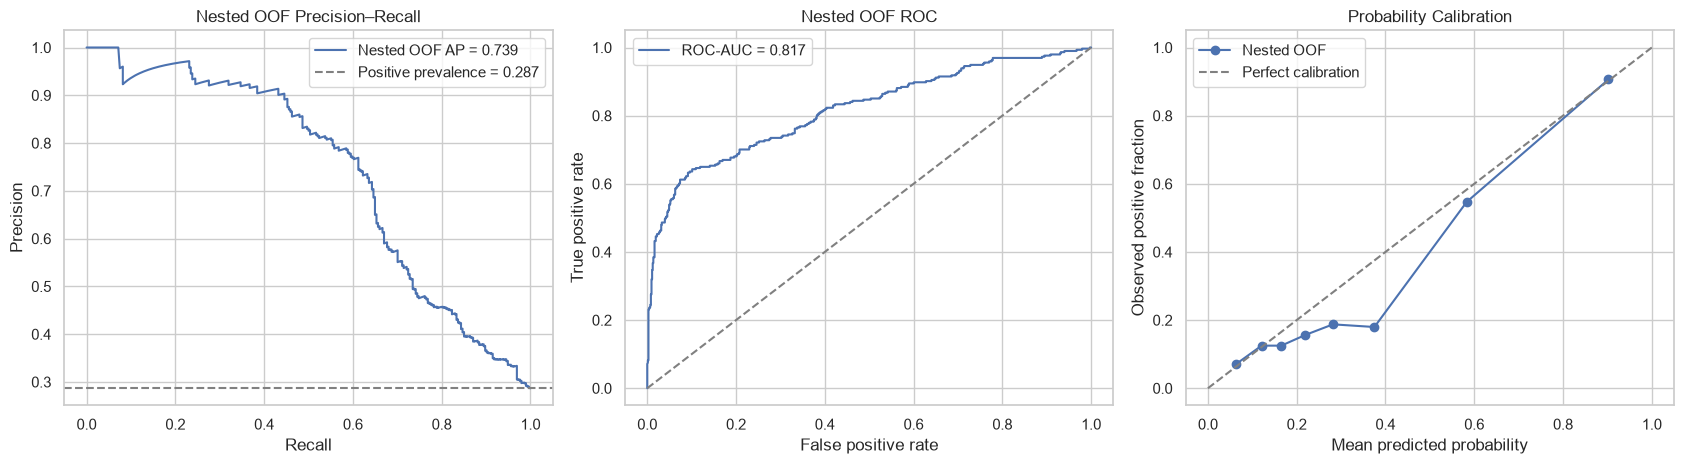

Saved: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\explainability_reliability\figures\06_oof_pr_roc_calibration.png
Interpretation: calibration is assessed on pooled nested OOF probabilities; bins can be noisy with a small dataset.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

precision, recall, _ = precision_recall_curve(y_oof, p_oof)
axes[0].plot(recall, precision, label=f"Nested OOF AP = {average_precision_score(y_oof, p_oof):.3f}")
axes[0].axhline(y_oof.mean(), linestyle="--", color="gray", label=f"Positive prevalence = {y_oof.mean():.3f}")
axes[0].set_title("Nested OOF Precision–Recall")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()

fpr, tpr, _ = roc_curve(y_oof, p_oof)
axes[1].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_oof, p_oof):.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_title("Nested OOF ROC")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend()

frac_pos, mean_pred = calibration_curve(y_oof, p_oof, n_bins=8, strategy="quantile")
axes[2].plot(mean_pred, frac_pos, marker="o", label="Nested OOF")
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
axes[2].set_title("Probability Calibration")
axes[2].set_xlabel("Mean predicted probability")
axes[2].set_ylabel("Observed positive fraction")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_oof_pr_roc_calibration.png", dpi=250, bbox_inches="tight")
plt.show()
print("Saved:", FIGURE_DIR / "06_oof_pr_roc_calibration.png")
print("Interpretation: calibration is assessed on pooled nested OOF probabilities; bins can be noisy with a small dataset.")

## Cell 7 — Error analysis: false positives and false negatives

Error counts at threshold 0.50:


,records
error_at_050,
CORRECT,856
FALSE_NEGATIVE,119
FALSE_POSITIVE,50


Error counts at the outer-training-OOF-selected thresholds:


,records
error_at_fold_threshold,
CORRECT,661
FALSE_POSITIVE,306
FALSE_NEGATIVE,58


Saved error review: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\explainability_reliability\tables\06_oof_error_review.csv


,source_row_index,name,CID,CAS,y_true,oof_probability,outer_fold,selected_family_in_fold,threshold_selected_from_outer_train_oof,error_at_fold_threshold,structure_group
773,9,Potassium iodide,4875,7681-11-0,1,0.022225,4,Random Forest — Morgan,0.175486,FALSE_NEGATIVE,ACYCLIC:[K+]
823,200,"1,3-dichloropropene (Ref: D D92)",24726,542-75-6,1,0.034478,4,Random Forest — Morgan,0.175486,FALSE_NEGATIVE,ACYCLIC:C=CC(Cl)Cl
775,15,"(1alpha,2alpha,3beta,4alpha,5alpha,6beta)-1,2,...",727,58-89-9,1,0.045105,4,Random Forest — Morgan,0.175486,FALSE_NEGATIVE,SCAFFOLD:C1CCCCC1
2,4,Tetradifon (Ref: ENT 23737),8305,116-29-0,1,0.056018,1,Extra Trees — Morgan,0.221503,FALSE_NEGATIVE,SCAFFOLD:O=S(=O)(c1ccccc1)c1ccccc1
786,74,Chlorobenzilate (Ref: ENT 18596),10522,510-15-6,1,0.057722,4,Random Forest — Morgan,0.175486,FALSE_NEGATIVE,SCAFFOLD:c1ccc(Cc2ccccc2)cc1
26,80,(Acetato-kappaO)phenylmercury,16682730,62-38-4,1,0.058567,1,Extra Trees — Morgan,0.221503,FALSE_NEGATIVE,SCAFFOLD:c1ccccc1
424,721,Nicosulfuron (Ref: DPX V9360),73281,111991-09-4,1,0.068260,2,Extra Trees — Morgan,0.243023,FALSE_NEGATIVE,SCAFFOLD:O=C(Nc1ncccn1)NS(=O)(=O)c1ccccn1
376,561,Diclobutrazol (Ref: PP296),53309,75736-33-3,1,0.073825,2,Extra Trees — Morgan,0.243023,FALSE_NEGATIVE,SCAFFOLD:c1ccc(CCn2cncn2)cc1
341,451,8-dodecenol,5283295,40642-40-8,1,0.075941,2,Extra Trees — Morgan,0.243023,FALSE_NEGATIVE,ACYCLIC:CCCC=CCCCCCCCO
282,124,L-ascorbic acid,54670067,50-81-7,1,0.113478,2,Extra Trees — Morgan,0.243023,FALSE_NEGATIVE,SCAFFOLD:O=C1C=CCO1


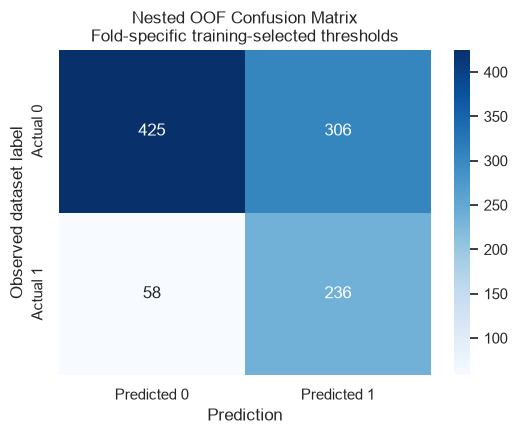

In [8]:
# Use fold-specific thresholds that were selected using only each outer-training fold's OOF predictions.
oof["error_at_050"] = np.select(
    [(oof["y_true"] == 1) & (oof["predicted_at_050"] == 0),
     (oof["y_true"] == 0) & (oof["predicted_at_050"] == 1)],
    ["FALSE_NEGATIVE", "FALSE_POSITIVE"], default="CORRECT"
)
oof["error_at_fold_threshold"] = np.select(
    [(oof["y_true"] == 1) & (oof["predicted_at_oof_threshold"] == 0),
     (oof["y_true"] == 0) & (oof["predicted_at_oof_threshold"] == 1)],
    ["FALSE_NEGATIVE", "FALSE_POSITIVE"], default="CORRECT"
)

print("Error counts at threshold 0.50:")
display(oof["error_at_050"].value_counts().rename("records").to_frame())
print("Error counts at the outer-training-OOF-selected thresholds:")
display(oof["error_at_fold_threshold"].value_counts().rename("records").to_frame())

review_cols = ["source_row_index", "name", "CID", "CAS", "y_true", "oof_probability", "outer_fold", "selected_family_in_fold", "threshold_selected_from_outer_train_oof", "error_at_fold_threshold", "structure_group"]
error_review = oof.loc[oof["error_at_fold_threshold"] != "CORRECT", review_cols].sort_values(["error_at_fold_threshold", "oof_probability"])
error_review.to_csv(TABLE_DIR / "06_oof_error_review.csv", index=False, encoding="utf-8-sig")
print("Saved error review:", TABLE_DIR / "06_oof_error_review.csv")
display(error_review.head(25))

cm = confusion_matrix(y_oof, pred_fold_threshold, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Predicted 0", "Predicted 1"], yticklabels=["Actual 0", "Actual 1"])
plt.title("Nested OOF Confusion Matrix\nFold-specific training-selected thresholds")
plt.xlabel("Prediction")
plt.ylabel("Observed dataset label")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_oof_confusion_matrix.png", dpi=250, bbox_inches="tight")
plt.show()

## Cell 8 — Applicability-domain support using max Tanimoto similarity

Max Tanimoto similarity to each record's outer-training pool:


,max_tanimoto_to_outer_training
count,1025.0000
mean,0.3960
std,0.1523
min,0.0000
25%,0.2778
50%,0.3788
75%,0.5000
max,1.0000


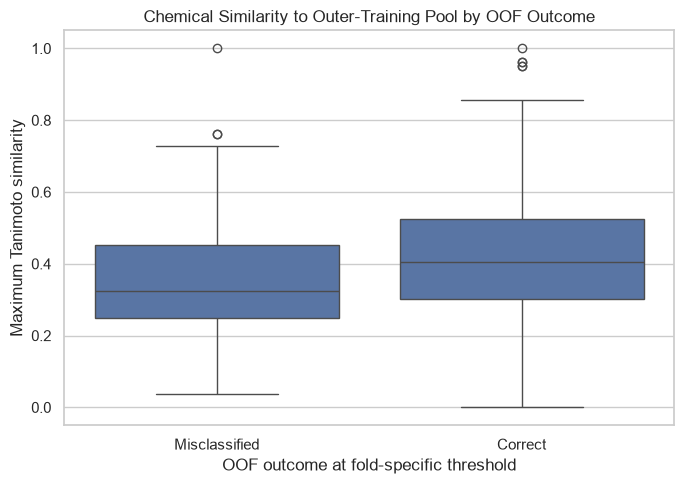

Saved applicability-domain table: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\explainability_reliability\tables\06_oof_applicability_domain.csv


In [9]:
# For each outer-fold OOF compound, compare its Morgan fingerprint only with records
# outside its own validation fold (the corresponding outer-training pool).
# A low maximum similarity is a warning about limited chemical-space support, not a toxicity verdict.
if "SMILES" not in metadata.columns:
    raise ValueError("Phase 03 metadata needs SMILES for the applicability-domain check.")

MORGAN_RADIUS = 2
MORGAN_BITS = int(X_morgan.shape[1])
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RADIUS, fpSize=MORGAN_BITS, includeChirality=False)
rdkit_fps = []
for smiles in metadata["SMILES"].astype(str):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        rdkit_fps.append(None)
    else:
        rdkit_fps.append(morgan_generator.GetFingerprint(mol))
if any(fp is None for fp in rdkit_fps):
    raise ValueError("Some baseline SMILES could not be parsed. Revisit Phase 03 before this analysis.")

# Map source row ID to feature-array index; metadata/arrays were checked for exact alignment.
row_to_idx = {int(row_id): idx for idx, row_id in enumerate(row_ids)}
oof_fold_by_row = dict(zip(oof["source_row_index"].astype(int), oof["outer_fold"].astype(int)))
neighbor_rows = []
for row in oof.itertuples(index=False):
    query_idx = row_to_idx[int(row.source_row_index)]
    fold_id = int(row.outer_fold)
    ref_indices = [i for i, rid in enumerate(row_ids) if oof_fold_by_row[int(rid)] != fold_id]
    similarities = DataStructs.BulkTanimotoSimilarity(rdkit_fps[query_idx], [rdkit_fps[i] for i in ref_indices])
    best_pos = int(np.argmax(similarities))
    best_idx = ref_indices[best_pos]
    neighbor_rows.append({
        "source_row_index": int(row.source_row_index),
        "outer_fold": fold_id,
        "max_tanimoto_to_outer_training": float(similarities[best_pos]),
        "nearest_training_name": str(metadata.iloc[best_idx]["name"]),
        "nearest_training_CID": metadata.iloc[best_idx]["CID"],
        "nearest_training_label": int(y[best_idx]),
    })

similarity_df = pd.DataFrame(neighbor_rows)
oof = oof.merge(similarity_df, on=["source_row_index", "outer_fold"], how="left", validate="one_to_one")
print("Max Tanimoto similarity to each record's outer-training pool:")
display(similarity_df["max_tanimoto_to_outer_training"].describe().to_frame().round(4))
similarity_df.to_csv(TABLE_DIR / "06_oof_applicability_domain.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(7, 5))
plot_df = oof.copy()
plot_df["outcome"] = np.where(plot_df["y_true"].to_numpy() == plot_df["predicted_at_oof_threshold"].to_numpy(), "Correct", "Misclassified")
sns.boxplot(data=plot_df, x="outcome", y="max_tanimoto_to_outer_training")
plt.title("Chemical Similarity to Outer-Training Pool by OOF Outcome")
plt.xlabel("OOF outcome at fold-specific threshold")
plt.ylabel("Maximum Tanimoto similarity")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_applicability_domain_similarity.png", dpi=250, bbox_inches="tight")
plt.show()
print("Saved applicability-domain table:", TABLE_DIR / "06_oof_applicability_domain.csv")

## Cell 9 — Inspect model uncertainty proxy (tree disagreement)

Maximum absolute difference between ensemble mean and model probability: 2.220446049250313e-16


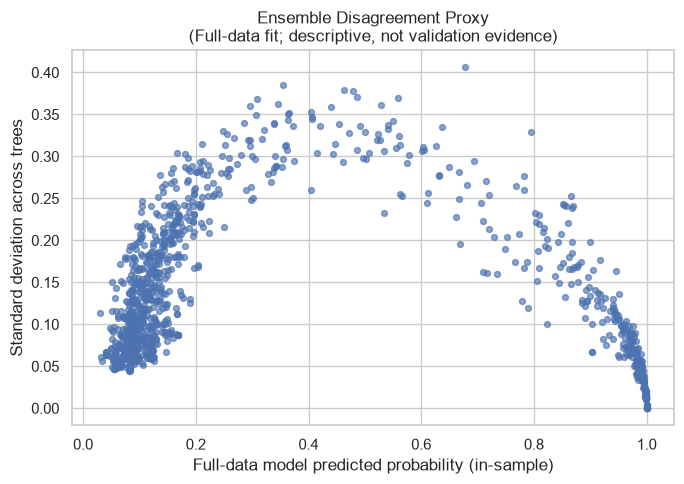

Saved tree-disagreement table. Do not treat it as calibrated uncertainty.


In [10]:
# Tree disagreement is a heuristic uncertainty proxy, not a calibrated probability interval.
if not hasattr(model, "estimators_"):
    print("Selected model does not expose individual trees; skipping tree-disagreement analysis.")
    ensemble_uncertainty_df = pd.DataFrame()
else:
    per_tree_probs = []
    for tree in model.estimators_:
        tree_probs = tree.predict_proba(X_model)
        classes = list(tree.classes_)
        positive_col = classes.index(1) if 1 in classes else None
        if positive_col is None:
            per_tree_probs.append(np.zeros(len(X_model)))
        else:
            per_tree_probs.append(tree_probs[:, positive_col])
    per_tree_probs = np.asarray(per_tree_probs, dtype=float)
    mean_tree_prob = per_tree_probs.mean(axis=0)
    std_tree_prob = per_tree_probs.std(axis=0, ddof=1)
    bundle_prob = model.predict_proba(X_model)[:, list(model.classes_).index(1)]
    print("Maximum absolute difference between ensemble mean and model probability:", float(np.max(np.abs(mean_tree_prob - bundle_prob))))

    ensemble_uncertainty_df = metadata[["source_row_index", "name", "CID", "label", "structure_group"]].copy()
    ensemble_uncertainty_df["full_model_probability_in_sample"] = bundle_prob
    ensemble_uncertainty_df["tree_probability_std_in_sample"] = std_tree_prob
    ensemble_uncertainty_df["tree_probability_iqr_in_sample"] = np.quantile(per_tree_probs, 0.75, axis=0) - np.quantile(per_tree_probs, 0.25, axis=0)
    ensemble_uncertainty_df.to_csv(TABLE_DIR / "06_full_model_tree_disagreement_in_sample.csv", index=False, encoding="utf-8-sig")

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(bundle_prob, std_tree_prob, alpha=0.65, s=18)
    ax.set_xlabel("Full-data model predicted probability (in-sample)")
    ax.set_ylabel("Standard deviation across trees")
    ax.set_title("Ensemble Disagreement Proxy\n(Full-data fit; descriptive, not validation evidence)")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "06_tree_disagreement_proxy.png", dpi=250, bbox_inches="tight")
    plt.show()
    print("Saved tree-disagreement table. Do not treat it as calibrated uncertainty.")

## Cell 10 — SHAP global explanation for the final candidate

Model family: Extra Trees — Morgan
Feature type: morgan
SHAP explanation sample: (100, 2048)
SHAP background sample: (50, 2048)
Top 20 SHAP features:


,feature,mean_abs_shap_value,mean_signed_shap_value
0,Morgan_bit_192,0.057724,-0.002627
1,Morgan_bit_695,0.018484,0.006270
2,Morgan_bit_601,0.017946,-0.001236
3,Morgan_bit_1754,0.017681,0.004742
4,Morgan_bit_345,0.016235,0.006765
5,Morgan_bit_1729,0.015211,0.001447
6,Morgan_bit_1917,0.012915,-0.002415
7,Morgan_bit_1203,0.011223,-0.001184
8,Morgan_bit_1896,0.009576,0.005530
9,Morgan_bit_1716,0.009185,-0.000620


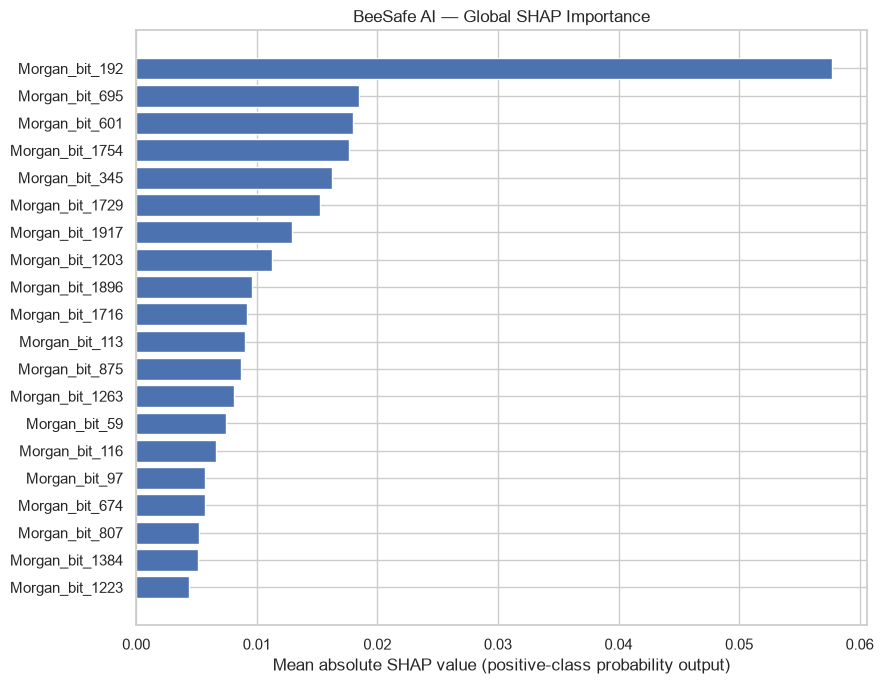

C:\Users\User\AppData\Local\Temp\ipykernel_14184\1456137.py:68: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


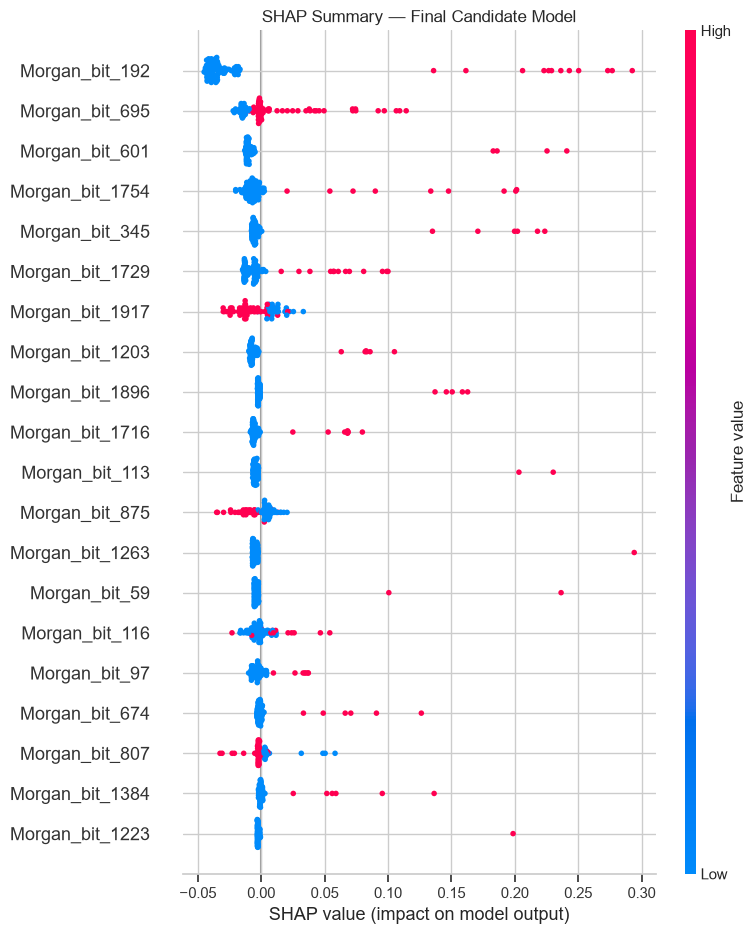

Global SHAP outputs saved.


In [11]:
# SHAP explains the final full-data candidate model. This is model interpretation, not OOF evaluation.
if feature_type == "morgan":
    feature_names = [f"Morgan_bit_{i}" for i in range(X_morgan.shape[1])]
    X_for_shap = X_morgan
else:
    feature_names = descriptor_names
    X_for_shap = X_desc

rng = np.random.default_rng(RANDOM_STATE)
shap_n = min(100, len(y))
shap_indices = np.sort(rng.choice(len(y), size=shap_n, replace=False))
background_n = min(50, len(y))
background_indices = np.sort(rng.choice(len(y), size=background_n, replace=False))
X_explain = X_for_shap[shap_indices]
X_background = X_for_shap[background_indices]

print("Model family:", model_family)
print("Feature type:", feature_type)
print("SHAP explanation sample:", X_explain.shape)
print("SHAP background sample:", X_background.shape)

# Probability-output SHAP is used so contributions correspond to the predicted positive-class probability.
# This can be slower for tree models with many features, but sample sizes are intentionally modest.
explainer = shap.TreeExplainer(
    model,
    data=X_background,
    feature_perturbation="interventional",
    model_output="probability"
)
shap_explanation = explainer(X_explain)
shap_values_all = np.asarray(shap_explanation.values)

# Normalise common SHAP output shapes to [samples, features] for class 1.
if shap_values_all.ndim == 3:
    if shap_values_all.shape[-1] == 2:
        shap_values_positive = shap_values_all[:, :, 1]
    elif shap_values_all.shape[1] == 2:
        shap_values_positive = shap_values_all[:, 1, :]
    else:
        raise ValueError(f"Unexpected multi-output SHAP shape: {shap_values_all.shape}")
elif shap_values_all.ndim == 2:
    shap_values_positive = shap_values_all
else:
    raise ValueError(f"Unexpected SHAP values shape: {shap_values_all.shape}")

mean_abs_shap = np.mean(np.abs(shap_values_positive), axis=0)
mean_signed_shap = np.mean(shap_values_positive, axis=0)
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap_value": mean_abs_shap,
    "mean_signed_shap_value": mean_signed_shap,
}).sort_values("mean_abs_shap_value", ascending=False).reset_index(drop=True)
shap_importance.to_csv(TABLE_DIR / "06_shap_global_feature_importance.csv", index=False, encoding="utf-8-sig")
print("Top 20 SHAP features:")
display(shap_importance.head(20).round(6))

plt.figure(figsize=(9, 7))
top_shap = shap_importance.head(20).sort_values("mean_abs_shap_value", ascending=True)
plt.barh(top_shap["feature"], top_shap["mean_abs_shap_value"])
plt.xlabel("Mean absolute SHAP value (positive-class probability output)")
plt.title("BeeSafe AI — Global SHAP Importance")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_shap_global_importance.png", dpi=250, bbox_inches="tight")
plt.show()

# SHAP summary plot: red/blue colours show high/low feature values, not toxicity classes.
plt.figure()
shap.summary_plot(
    shap_values_positive,
    X_explain,
    feature_names=feature_names,
    max_display=20,
    show=False
)
plt.title("SHAP Summary — Final Candidate Model")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_shap_summary.png", dpi=250, bbox_inches="tight")
plt.show()
print("Global SHAP outputs saved.")

## Cell 11 — Map influential Morgan bits to example substructures

In [12]:
# A Morgan bit may represent multiple environments because fingerprints are hashed.
# Therefore this is an example mapping, not a one-to-one chemical explanation.
if feature_type != "morgan":
    print("The final model uses descriptors rather than Morgan fingerprints; skipping atom/substructure mapping.")
    bit_fragment_examples = pd.DataFrame()
else:
    top_bits = [int(str(f).replace("Morgan_bit_", "")) for f in shap_importance.head(20)["feature"]]
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=MORGAN_BITS, includeChirality=False)
    fragment_rows = []
    found_bits = set()
    max_examples_per_bit = 3

    for idx, row in metadata.iterrows():
        if len(found_bits) == len(top_bits) and all(sum(r["bit_id"] == b for r in fragment_rows) >= max_examples_per_bit for b in top_bits):
            break
        mol = Chem.MolFromSmiles(str(row["SMILES"]))
        if mol is None:
            continue
        additional = rdFingerprintGenerator.AdditionalOutput()
        additional.CollectBitInfoMap()
        generator.GetFingerprint(mol, additionalOutput=additional)
        bit_info = additional.GetBitInfoMap()
        for bit_id in top_bits:
            if bit_id not in bit_info or sum(r["bit_id"] == bit_id for r in fragment_rows) >= max_examples_per_bit:
                continue
            atom_radius_pairs = bit_info[bit_id]
            for atom_id, radius in atom_radius_pairs[:1]:
                bonds = list(Chem.FindAtomEnvironmentOfRadiusN(mol, int(radius), int(atom_id)))
                atom_set = {int(atom_id)}
                for bond_idx in bonds:
                    bond = mol.GetBondWithIdx(int(bond_idx))
                    atom_set.add(bond.GetBeginAtomIdx())
                    atom_set.add(bond.GetEndAtomIdx())
                try:
                    frag = Chem.MolFragmentToSmiles(mol, atomsToUse=sorted(atom_set), bondsToUse=bonds, canonical=True)
                except Exception:
                    frag = "fragment extraction failed"
                fragment_rows.append({
                    "bit_id": bit_id,
                    "mean_abs_shap_value": float(shap_importance.loc[shap_importance["feature"] == f"Morgan_bit_{bit_id}", "mean_abs_shap_value"].iloc[0]),
                    "example_name": row["name"],
                    "example_CID": row["CID"],
                    "example_fragment_smiles": frag,
                    "center_atom_index": int(atom_id),
                    "radius": int(radius),
                })
                found_bits.add(bit_id)
                break

    bit_fragment_examples = pd.DataFrame(fragment_rows).drop_duplicates(subset=["bit_id", "example_CID", "example_fragment_smiles"])
    bit_fragment_examples.to_csv(TABLE_DIR / "06_morgan_bit_substructure_examples.csv", index=False, encoding="utf-8-sig")
    print("Example substructure mappings for top SHAP bits:")
    display(bit_fragment_examples.head(30))
    print("Reminder: hashed fingerprint collisions are possible; examples are not unique definitions of each bit.")

Example substructure mappings for top SHAP bits:


,bit_id,mean_abs_shap_value,example_name,example_CID,example_fragment_smiles,center_atom_index,radius
0,1917,0.012915,Ethanedioic acid,971,C=O,0,1
1,807,0.005222,Ethanedioic acid,971,C,1,0
2,1917,0.012915,Benzoic acid,243,C=O,0,1
3,807,0.005222,Benzoic acid,243,C,1,0
4,875,0.008683,Tetradifon (Ref: ENT 23737),8305,ccc,11,1
5,192,0.057724,"S-[(1,3-Dihydro-1,3-dioxo-2H-isoindol-2-yl)met...",12901,P,2,0
6,695,0.018484,"S-[(1,3-Dihydro-1,3-dioxo-2H-isoindol-2-yl)met...",12901,O,1,0
7,601,0.017946,"S-[(1,3-Dihydro-1,3-dioxo-2H-isoindol-2-yl)met...",12901,COP,1,1
8,1729,0.015211,"S-[(1,3-Dihydro-1,3-dioxo-2H-isoindol-2-yl)met...",12901,P=S,3,1
9,116,0.006611,"S-[(1,3-Dihydro-1,3-dioxo-2H-isoindol-2-yl)met...",12901,S,6,0


Reminder: hashed fingerprint collisions are possible; examples are not unique definitions of each bit.


## Cell 12 — Local explanation for a high-scoring example molecule

Example compound: 1-Naphthalenol methylcarbamate
CID: 6129
Observed dataset label: 1
Full-data model probability: 1.0
Saved screening threshold: 0.2556
Important: full-data model probability is in-sample and can be optimistic.


,feature,feature_value,shap_value_positive_class,absolute_shap
0,Morgan_bit_345,1.0,0.225541,0.225541
1,Morgan_bit_1896,1.0,0.151804,0.151804
2,Morgan_bit_1729,1.0,0.105573,0.105573
3,Morgan_bit_695,1.0,0.074096,0.074096
4,Morgan_bit_1889,1.0,0.058664,0.058664
5,Morgan_bit_1430,1.0,0.041941,0.041941
6,Morgan_bit_1758,1.0,0.034656,0.034656
7,Morgan_bit_192,0.0,-0.019188,0.019188
8,Morgan_bit_601,0.0,-0.005975,0.005975
9,Morgan_bit_1917,1.0,0.005118,0.005118


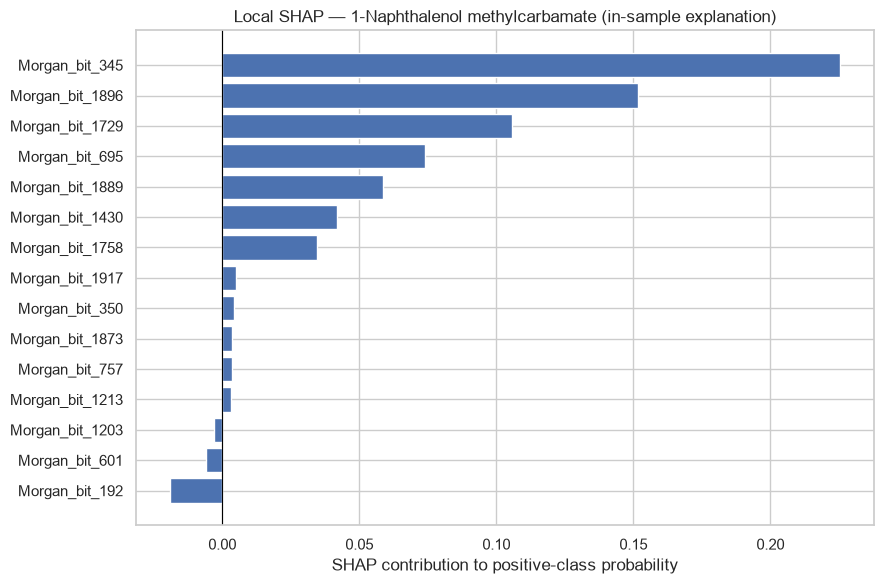

In [13]:
# This selected example is from the full-data fitted model and is therefore an in-sample explanation.
# It is useful for understanding model behaviour, but not as a held-out prediction demonstration.
full_model_prob = model.predict_proba(X_model)[:, list(model.classes_).index(1)]
example_idx = int(np.argmax(full_model_prob))
example_row = metadata.iloc[example_idx]
example_prob = float(full_model_prob[example_idx])
example_threshold = float(model_bundle.get("threshold", 0.5))

print("Example compound:", example_row["name"])
print("CID:", example_row["CID"])
print("Observed dataset label:", int(y[example_idx]))
print("Full-data model probability:", round(example_prob, 4))
print("Saved screening threshold:", round(example_threshold, 4))
print("Important: full-data model probability is in-sample and can be optimistic.")

shap_row_positions = np.where(shap_indices == example_idx)[0]
if len(shap_row_positions) == 0:
    # Compute a local explanation for the chosen molecule only.
    local_explanation = explainer(X_model[example_idx:example_idx+1])
    local_all = np.asarray(local_explanation.values)
    if local_all.ndim == 3:
        local_values = local_all[0, :, 1] if local_all.shape[-1] == 2 else local_all[0, 1, :]
    else:
        local_values = local_all[0]
else:
    local_values = shap_values_positive[int(shap_row_positions[0])]

local_df = pd.DataFrame({
    "feature": feature_names,
    "feature_value": X_model[example_idx].astype(float),
    "shap_value_positive_class": local_values,
})
local_df["absolute_shap"] = local_df["shap_value_positive_class"].abs()
local_df = local_df.sort_values("absolute_shap", ascending=False).reset_index(drop=True)
local_df.to_csv(TABLE_DIR / "06_local_explanation_high_score_example.csv", index=False, encoding="utf-8-sig")
display(local_df.head(20))

plt.figure(figsize=(9, 6))
local_top = local_df.head(15).sort_values("shap_value_positive_class")
plt.barh(local_top["feature"], local_top["shap_value_positive_class"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("SHAP contribution to positive-class probability")
plt.title(f"Local SHAP — {example_row['name']} (in-sample explanation)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_local_shap_high_score_example.png", dpi=250, bbox_inches="tight")
plt.show()

## Cell 13 — Save Phase 06 summary and verify outputs

In [14]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

outputs = sorted(str(p.relative_to(PROJECT_ROOT)) for p in REPORT_DIR.rglob("*") if p.is_file())
summary = {
    "project": "BeeSafe AI",
    "phase": "06 — Explainable AI and Model Reliability",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "model_family": str(model_family),
    "feature_type": str(feature_type),
    "model_bundle_path": str(MODEL_PATH),
    "n_baseline_records": int(len(y)),
    "n_nested_oof_records": int(len(oof)),
    "nested_oof_average_precision": float(probability_metrics["nested_oof_average_precision"]),
    "nested_oof_roc_auc": float(probability_metrics["nested_oof_roc_auc"]),
    "nested_oof_brier_score": float(probability_metrics["nested_oof_brier_score"]),
    "nested_oof_log_loss": float(probability_metrics["nested_oof_log_loss"]),
    "threshold_saved_in_model_bundle": float(threshold),
    "shap_explanation_sample_size": int(len(shap_indices)),
    "shap_feature_count": int(len(feature_names)),
    "applicability_domain_method": "maximum Morgan radius-2 Tanimoto similarity to outer-training records for each nested OOF validation record",
    "uncertainty_proxy": "standard deviation and IQR of per-tree predicted probabilities for final full-data fit; descriptive/in-sample only",
    "limitations": [
        "Model predicts ApisTox dataset-defined toxicity labels, not direct field-level ecological harm.",
        "SHAP describes the final full-data model; local explanations for those fitted records are not out-of-sample validation.",
        "Morgan bits are hashed features; bit-to-substructure examples are potentially ambiguous due to collisions.",
        "Ensemble tree disagreement is a heuristic proxy, not a calibrated predictive interval.",
        "Calibration and reliability estimates are based on nested grouped OOF predictions and remain limited by dataset size.",
        "External/prospective validation is required before strong scientific or practical claims."
    ],
    "output_files": outputs,
}
SUMMARY_PATH = REPORT_DIR / "06_explainability_reliability_summary.json"
with SUMMARY_PATH.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

print("=" * 72)
print("BEESAFE AI — PHASE 06 COMPLETE")
print("=" * 72)
print("Selected Phase 05 candidate:", model_family)
print("Nested OOF AP:", round(probability_metrics["nested_oof_average_precision"], 4))
print("Nested OOF ROC-AUC:", round(probability_metrics["nested_oof_roc_auc"], 4))
print("SHAP sample size:", len(shap_indices))
print("Outputs:", REPORT_DIR)
print("Summary:", SUMMARY_PATH)
print("Original features, model and labels were not modified.")
display(pd.DataFrame([
    {"artifact": "06_nested_oof_metrics.json", "purpose": "Out-of-fold reliability metrics"},
    {"artifact": "06_oof_error_review.csv", "purpose": "False positives/negatives to inspect"},
    {"artifact": "06_oof_applicability_domain.csv", "purpose": "Similarity to outer-training chemical space"},
    {"artifact": "06_shap_global_feature_importance.csv", "purpose": "Global model explanation"},
    {"artifact": "06_morgan_bit_substructure_examples.csv", "purpose": "Illustrative fragments for high-impact fingerprint bits"},
    {"artifact": "06_explainability_reliability_summary.json", "purpose": "Reproducibility summary and limitations"},
]))

BEESAFE AI — PHASE 06 COMPLETE
Selected Phase 05 candidate: Extra Trees — Morgan
Nested OOF AP: 0.7391
Nested OOF ROC-AUC: 0.8174
SHAP sample size: 100
Outputs: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\explainability_reliability
Summary: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\explainability_reliability\06_explainability_reliability_summary.json
Original features, model and labels were not modified.


,artifact,purpose
0,06_nested_oof_metrics.json,Out-of-fold reliability metrics
1,06_oof_error_review.csv,False positives/negatives to inspect
2,06_oof_applicability_domain.csv,Similarity to outer-training chemical space
3,06_shap_global_feature_importance.csv,Global model explanation
4,06_morgan_bit_substructure_examples.csv,Illustrative fragments for high-impact fingerp...
5,06_explainability_reliability_summary.json,Reproducibility summary and limitations


## Interpretation checklist

Before using Phase 06 outputs in a report, check:
1. **Nested OOF metrics** are the reliability evidence; the final full-data model's in-sample probabilities are only for explanation and descriptive tree disagreement.
2. **SHAP values** describe the model's learned associations, not causal toxicology mechanisms.
3. **Low Tanimoto similarity** indicates weaker representation in the outer-training chemical space; it is not itself proof of unreliable or toxic behavior.
4. **Calibration curves** can be noisy at this dataset size; don't call predicted values calibrated unless the evidence supports it.
5. The system screens the ApisTox toxicity labels. It is not a regulatory decision engine or a substitute for laboratory or field studies.

**Next phase:** once this notebook has run and the artifacts are reviewed, we can build the Streamlit application and model inference workflow.